# How fast does the ARAM Mayhem meta move?
## Win-rate persistence across 24 patches on the China server

**Question.** When a champion sits at 56% win rate on the current patch, how much of that should we expect to still be there next patch, in three patches, in six months? Equivalently: how much of the patch-to-patch movement in a champion's win rate is *real* (balance changes, meta shifts) and how much is sampling noise, and what is the best way to forecast the next patch's tier list from the history we already have?

**Why it matters.** DeepARAM's tier list combines patches by estimated games (`data/cn/history/by_patch.json`). Whether that is the right choice depends on the answer: if win rates are noisy, averaging many patches helps; if they are precise but drift, the newest patch should dominate.

**Data.** Tencent's official Mayhem stats for the China server (`data/cn/history/`), 24 patches from 15.21 (Oct 2025) to 16.21 (Oct 2026), 171 to 173 champions each, plus the daily cumulative snapshots behind them (361 days). Sample sizes are not published, which is the main thing this notebook has to work around.

**TL;DR**

1. Win rates are **very persistent**: the correlation between one patch and the next is 0.94, and it is still 0.64 twelve patches (about six months) later. Roughly half of a champion's advantage is a permanent trait; the rest is a transient with a half-life of about 6 patches (three months).
2. The patch-to-patch movement is **almost entirely real**. Splitting each patch into two halves, the two halves agree at r = 0.99+ (half-to-half differences have an SD of about 0.3 pp, against 1.2 pp between consecutive patches). Sampling noise is negligible at Tencent's volume, so an averaged tier list trades away freshness and gains nothing.
3. **The newest patch alone is the best forecast** of the next patch (mean absolute error 0.75 pp). Averaging the last three patches is worse (0.88 pp), averaging everything is twice as bad (1.38 pp), and an exponentially weighted average does not beat the latest patch at any weight.
4. **Players chase winners, with a one-patch lag.** A champion whose win rate rises this patch is picked more *next* patch (Spearman 0.21 between the two changes, p < 1e-39), while a rise in pick rate does not predict a change in win rate (Spearman -0.02, p = 0.24). Popularity follows strength, not the other way round.

## 1. Setup and data

Everything runs offline from files in this repository. The notebook finds the repo root by walking up from its own folder.

In [1]:
from pathlib import Path
import glob, json, warnings
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import curve_fit
import statsmodels.formula.api as smf
import matplotlib as mpl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "cn" / "history").exists():
    ROOT = ROOT.parent
FIG = ROOT / "analysis" / "win-rate-persistence"
HIST = ROOT / "data" / "cn" / "history"

# One consistent palette (categorical slots in fixed order) and recessive axes.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#6250d6",
     "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "axes.edgecolor": C["ink2"], "axes.labelcolor": C["ink"], "axes.titlecolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "legend.frameon": False, "font.size": 10,
})
def pct(ax, axis="y", d=0):
    f = mpl.ticker.PercentFormatter(1.0, decimals=d)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, bbox_inches="tight"); plt.show()

In [2]:
patches = pd.read_csv(HIST / "patches.csv", dtype={"patch": str}, parse_dates=["released", "window_start", "first_day_in_data", "last_day"])
bp = pd.read_csv(HIST / "by_patch.csv", dtype={"patch": str})      # one row per champion x patch (Tencent's final numbers for the window)
daily = pd.concat(pd.read_csv(f, dtype={"date": str}) for f in sorted(glob.glob(str(HIST / "daily" / "*.csv"))))
daily["date"] = pd.to_datetime(daily["date"])

ORDER = list(patches["patch"])                    # chronological; patch is a string because "16.10" != "16.1"
P = {p: i for i, p in enumerate(ORDER)}
bp["t"] = bp["patch"].map(P)
names = bp.drop_duplicates("champion_id").set_index("champion_id")["name"]

print(f"{len(ORDER)} patches, {bp.champion_id.nunique()} champions, {len(bp)} champion-patch rows, "
      f"{len(daily)} daily rows from {daily.date.min().date()} to {daily.date.max().date()}")
patches.assign(released=patches.released.dt.date, last_day=patches.last_day.dt.date)[["patch", "released", "last_day", "days"]].set_index("patch").T

24 patches, 173 champions, 4133 champion-patch rows, 62172 daily rows from 2025-11-02 to 2026-10-28


patch,15.21,15.22,15.23,15.24,16.1,16.2,16.3,16.5,16.6,16.7,...,16.12,16.13,16.14,16.15,16.16,16.17,16.18,16.19,16.20,16.21
released,2025-10-23,2025-11-06,2025-11-20,2025-12-04,2026-01-08,2026-01-22,2026-02-04,2026-03-05,2026-03-19,2026-04-01,...,2026-06-11,2026-06-25,2026-07-16,2026-07-30,2026-08-13,2026-08-27,2026-09-10,2026-09-23,2026-10-09,2026-10-22
last_day,2025-11-05,2025-11-19,2025-12-03,2026-01-07,2026-01-21,2026-02-03,2026-03-04,2026-03-18,2026-03-31,2026-04-15,...,2026-06-24,2026-07-15,2026-07-29,2026-08-12,2026-08-26,2026-09-09,2026-09-22,2026-10-11,2026-10-21,2026-10-28
days,14,14,14,35,14,13,29,14,13,15,...,14,21,14,14,14,14,13,19,10,7


Each patch row is Tencent's cumulative number over that patch's window, so a champion-patch win rate is a true multi-week average, not a snapshot. Pick rate is the share of games the champion appears in. Nothing here is a sample count.

**Wide matrices.** Most of the analysis works on a champions x patches matrix of win rates (and one of pick rates). Champions released or missing mid-year show up as `NaN` for the patches they were absent.

In [3]:
W = bp.pivot(index="champion_id", columns="t", values="win_rate")    # win rate
K = bp.pivot(index="champion_id", columns="t", values="pick_rate")   # pick rate

spread = bp.groupby("t")["win_rate"].agg(mean="mean", sd="std", lo="min", hi="max")
spread.index = ORDER
print("Across-champion SD of win rate per patch (pp):")
print((spread["sd"] * 100).round(2).to_string())

Across-champion SD of win rate per patch (pp):
15.21    3.11
15.22    3.68
15.23    3.12
15.24    2.94
16.1     3.10
16.2     3.20
16.3     2.84
16.5     2.98
16.6     2.95
16.7     3.05
16.8     2.95
16.9     2.98
16.10    2.98
16.11    2.92
16.12    3.57
16.13    4.10
16.14    3.84
16.15    3.71
16.16    3.68
16.17    3.09
16.18    3.05
16.19    3.02
16.20    2.99
16.21    2.73


The spread between champions is about 3 pp (SD) on a typical patch, widening to 3.7 to 4.1 pp in the 16.13 to 16.16 window (a mid-year rework period on the live mode where a few champions dropped to 36%) and tightening to 2.7 pp on the current patch 16.21. That spread is the "signal" a tier list is trying to rank. The question is how much of it survives from one patch to the next.

## 2. How persistent is a champion's win rate?

### 2.1 This patch vs next patch

Pooling every consecutive pair of patches (23 transitions, about 3,950 champion-transitions) and regressing next patch's win rate on this patch's gives the amount of *regression to the mean* a tier list should expect. A slope of 1 means no reversion; a slope of 0 means last patch tells you nothing. Standard errors are clustered by champion because the same champion contributes 23 rows.

slope 0.929 (95% CI 0.915 to 0.942), Pearson r 0.936, Spearman rho 0.933, n = 3959
A champion 10 pp above average this patch is expected 9.3 pp above average next patch.


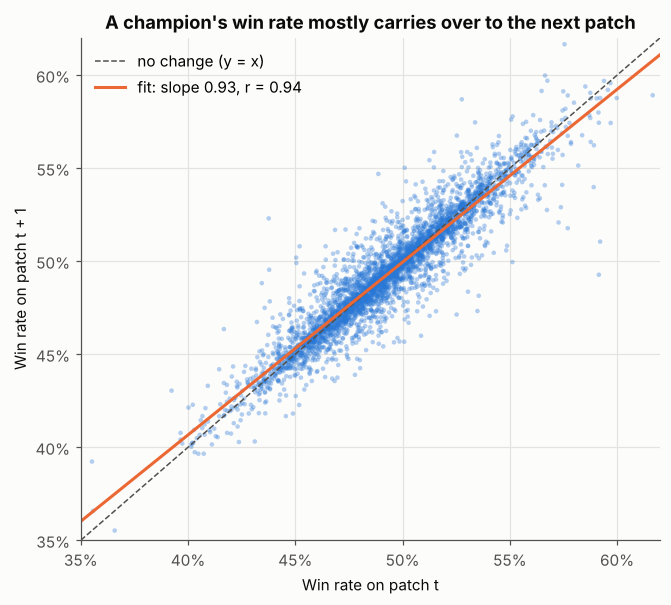

In [4]:
pairs = []
for t in range(len(ORDER) - 1):
    d = pd.DataFrame({"wr": W[t], "wr_next": W[t + 1], "pick": K[t], "pick_next": K[t + 1]}).dropna()
    d["t"] = t; d["champion_id"] = d.index
    pairs.append(d)
pairs = pd.concat(pairs, ignore_index=True)

m1 = smf.ols("wr_next ~ wr", pairs).fit(cov_type="cluster", cov_kwds={"groups": pairs["champion_id"]})
slope, (lo, hi) = m1.params["wr"], m1.conf_int().loc["wr"]
r_lag1 = stats.pearsonr(pairs.wr, pairs.wr_next)[0]
rho_lag1 = stats.spearmanr(pairs.wr, pairs.wr_next)[0]
print(f"slope {slope:.3f} (95% CI {lo:.3f} to {hi:.3f}), Pearson r {r_lag1:.3f}, Spearman rho {rho_lag1:.3f}, n = {len(pairs)}")
print(f"A champion 10 pp above average this patch is expected {10*slope:.1f} pp above average next patch.")

fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.scatter(pairs.wr, pairs.wr_next, s=9, alpha=0.35, color=C["blue"], edgecolor="none")
xx = np.linspace(0.35, 0.62, 2)
ax.plot(xx, xx, color=C["ink2"], lw=1, ls="--", label="no change (y = x)")
ax.plot(xx, m1.params["Intercept"] + slope * xx, color=C["orange"], lw=2, label=f"fit: slope {slope:.2f}, r = {r_lag1:.2f}")
ax.set_xlim(0.35, 0.62); ax.set_ylim(0.35, 0.62); pct(ax, "x"); pct(ax, "y")
ax.set_xlabel("Win rate on patch t"); ax.set_ylabel("Win rate on patch t + 1")
ax.set_title("A champion's win rate mostly carries over to the next patch")
ax.legend(loc="upper left")
save(fig, "fig1_next_patch_scatter.png")

### 2.2 How quickly does the correlation decay?

Lag-*k* correlation: for every pair of patches *k* apart, correlate the champions' win rates, then average over pairs. If each patch were an independent draw the correlation would drop to the long-run reliability immediately; if balance changes accumulate as a random walk it would decay towards zero. A convenient model that nests both is

$$ r(k) = a + (1 - a)\,\phi^{k} $$

where *a* is the share of between-champion variance that is permanent (a champion's identity: kit, Mayhem modifiers, how well it suits the mode) and *phi* is how much of the transient part (current balance numbers, meta) survives one patch. The half-life of the transient part is $\ln 0.5 / \ln \phi$ patches.

     pearson   p_lo   p_hi  spearman   n
lag                                     
1      0.940  0.749  0.996     0.934  23
2      0.896  0.739  0.986     0.887  22
3      0.862  0.719  0.957     0.854  21
4      0.826  0.695  0.952     0.820  20
5      0.789  0.640  0.930     0.784  19
6      0.767  0.623  0.909     0.762  18
7      0.746  0.563  0.853     0.742  17
8      0.728  0.524  0.813     0.727  16
9      0.717  0.571  0.795     0.712  15
10     0.697  0.564  0.758     0.690  14
11     0.666  0.516  0.746     0.659  13
12     0.639  0.518  0.739     0.631  12

fit: permanent share a = 0.55 (se 0.03), transient persistence phi = 0.89 (se 0.01), transient half-life = 5.7 patches


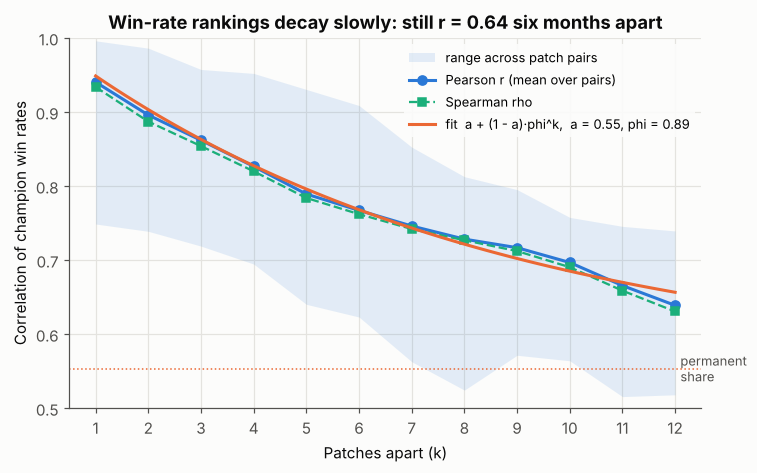

In [5]:
lags = range(1, 13)
rows = []
for k in lags:
    for t in range(len(ORDER) - k):
        m = W[t].notna() & W[t + k].notna()
        rows.append({"lag": k, "t": t, "pearson": stats.pearsonr(W[t][m], W[t + k][m])[0],
                     "spearman": stats.spearmanr(W[t][m], W[t + k][m])[0]})
lagdf = pd.DataFrame(rows)
corr = lagdf.groupby("lag").agg(pearson=("pearson", "mean"), p_lo=("pearson", "min"), p_hi=("pearson", "max"),
                                spearman=("spearman", "mean"), n=("pearson", "size"))

model = lambda k, a, phi: a + (1 - a) * phi ** k
(a_hat, phi_hat), cov = curve_fit(model, corr.index.values, corr["pearson"].values, p0=(0.5, 0.9), bounds=([0, 0], [1, 1]))
a_se, phi_se = np.sqrt(np.diag(cov))
half_life = np.log(0.5) / np.log(phi_hat)
print(corr.round(3))
print(f"\nfit: permanent share a = {a_hat:.2f} (se {a_se:.2f}), transient persistence phi = {phi_hat:.2f} (se {phi_se:.2f}), "
      f"transient half-life = {half_life:.1f} patches")

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.fill_between(corr.index, corr.p_lo, corr.p_hi, color=C["blue"], alpha=0.12, lw=0, label="range across patch pairs")
ax.plot(corr.index, corr.pearson, "o-", color=C["blue"], lw=2, ms=6, label="Pearson r (mean over pairs)")
ax.plot(corr.index, corr.spearman, "s--", color=C["aqua"], lw=1.5, ms=5, label="Spearman rho")
kk = np.linspace(1, 12, 100)
ax.plot(kk, model(kk, a_hat, phi_hat), color=C["orange"], lw=2, label=f"fit  a + (1 - a)·phi^k,  a = {a_hat:.2f}, phi = {phi_hat:.2f}")
ax.axhline(a_hat, color=C["orange"], lw=1, ls=":")
ax.text(12.1, a_hat, "permanent\nshare", va="center", fontsize=8.5, color=C["ink2"])
ax.set_ylim(0.5, 1.0); ax.set_xlim(0.5, 12.5); ax.set_xticks(list(lags))
ax.set_xlabel("Patches apart (k)"); ax.set_ylabel("Correlation of champion win rates")
ax.set_title("Win-rate rankings decay slowly: still r = 0.64 six months apart")
ax.legend(loc="upper right", fontsize=8.5, frameon=True, facecolor=C["surface"], edgecolor="none", framealpha=0.9)
save(fig, "fig2_correlogram.png")

The decay is slow and smooth. The fitted model says roughly **half of the between-champion spread is permanent** (a = 0.55: the correlation flattens towards that floor rather than zero), and the other half is a transient whose persistence is 0.89 per patch, i.e. a **half-life of about 6 patches** (three months). Spearman and Pearson agree closely, so this is not driven by a few outliers.

Caveats on the fit: the twelve lag correlations are averages over overlapping patch pairs, so they are not independent observations and the standard errors from `curve_fit` understate the real uncertainty. The shaded band (min to max over pairs at each lag) is the honest picture: lag-1 correlations range from 0.75 (the 16.12 to 16.13 transition, a large mid-year rework) to 0.996 depending on how big the patch was.

## 3. Is the patch-to-patch movement real, or just noise?

A correlation below 1 between two patches can come from two sources: the game changed (balance patches, new augments, meta), or the win rates themselves are imprecise. Tencent does not publish sample sizes, so the usual binomial standard error is unavailable. Two workarounds:

**(a) Does the residual scatter depend on pick rate?** Sampling noise scales with $1/\sqrt{n}$, and *n* is proportional to pick rate, so if noise mattered, rarely picked champions would bounce around more than popular ones.

**(b) Split-half reliability within a patch.** The daily files are cumulative since the window opened, so with games estimated as `pick_rate x days` (the same convention as `data/cn/query.py`) the second half of a window can be recovered by subtraction: $\mathrm{wr}_2 = (\mathrm{wr}_{\text{all}} g_{\text{all}} - \mathrm{wr}_1 g_1) / (g_{\text{all}} - g_1)$. Within one patch there are no balance changes (hotfixes aside), so the disagreement between the two halves is a direct measurement of noise.

In [6]:
# (a) residual spread by pick-rate quintile, using each champion's deviation from its own 24-patch mean
bp["dev"] = bp["win_rate"] - bp.groupby("champion_id")["win_rate"].transform("mean")
bp["pick_q"] = pd.qcut(bp["pick_rate"], 5, labels=["lowest 20%", "20-40%", "40-60%", "60-80%", "top 20%"])
print("SD of a champion's deviation from its own mean, by pick-rate quintile (pp):")
print((bp.groupby("pick_q", observed=True)["dev"].std() * 100).round(2).to_string())
print("Spearman(pick rate, |deviation|) =", round(stats.spearmanr(bp.pick_rate, bp.dev.abs())[0], 3))

SD of a champion's deviation from its own mean, by pick-rate quintile (pp):
pick_q
lowest 20%    1.58
20-40%        1.74
40-60%        1.59
60-80%        1.58
top 20%       1.81
Spearman(pick rate, |deviation|) = 0.021


In [7]:
# (b) split-half reliability inside each patch window
half_rows, half_diff = [], []
for _, p in patches.iterrows():
    days = int(p["days"])
    if days < 10 or p["first_day_in_data"] > p["window_start"] + pd.Timedelta(days=days // 2 - 1):
        continue            # 15.21 began before the API's first day; 16.21 is still live
    mid = p["window_start"] + pd.Timedelta(days=days // 2 - 1)
    a = daily[daily.date == mid].set_index("champion_id")
    b = daily[daily.date == p["last_day"]].set_index("champion_id")
    n1, n2 = (mid - p["window_start"]).days + 1, days
    g1, g2 = a.pick_rate * n1, b.pick_rate * n2
    j = pd.DataFrame({"wr1": a.win_rate, "wr2": (b.win_rate * g2 - a.win_rate * g1) / (g2 - g1),
                      "pick": b.pick_rate}).dropna()
    r = stats.pearsonr(j.wr1, j.wr2)[0]
    half_rows.append({"patch": p["patch"], "days": days, "champions": len(j), "r_halves": r,
                      "reliability_full": 2 * r / (1 + r), "sd_diff_pp": 100 * (j.wr1 - j.wr2).std()})
    half_diff.append(j.assign(patch=p["patch"]))
halves = pd.DataFrame(half_rows).set_index("patch")
half_diff = pd.concat(half_diff)
print(halves.round(3))
typical = halves.drop(["15.23", "16.12"])
print(f"\nMedian split-half r = {halves.r_halves.median():.3f}; Spearman-Brown reliability of a whole patch = {halves.reliability_full.median():.3f}")
print(f"SD of half-vs-half difference: median {halves.sd_diff_pp.median():.2f} pp (excluding 15.23 and 16.12: {typical.sd_diff_pp.median():.2f} pp)")

       days  champions  r_halves  reliability_full  sd_diff_pp
patch                                                         
15.22    14        171     0.996             0.998       0.312
15.23    14        172     0.825             0.904       2.023
15.24    35        172     0.949             0.974       0.953
16.1     14        172     0.993             0.996       0.380
16.2     13        172     0.996             0.998       0.310
16.3     29        172     0.991             0.996       0.377
16.5     14        172     0.992             0.996       0.378
16.6     13        172     0.998             0.999       0.197
16.7     15        172     0.998             0.999       0.195
16.8     13        172     0.998             0.999       0.182
16.9     15        172     0.988             0.994       0.477
16.10    14        172     0.998             0.999       0.188
16.11    14        172     0.997             0.998       0.247
16.12    14        172     0.936             0.967     

Both checks point the same way. The residual spread is flat across pick-rate quintiles (1.6 to 1.8 pp, no trend), which is what you see when sampling noise is negligible compared with real change. And inside a patch, the two halves agree at **r = 0.99 or better** on 20 of 22 patches, with half-vs-half differences of only about **0.2 to 0.4 pp** per champion.

Two patches stand out: **15.23 (r = 0.82)** and **16.12 (r = 0.94)**. Either something changed mid-window (a hotfix, or an augment pool change) or the patch-window boundary in `patches.csv` is slightly off for those two. That is worth a look in the project's patch-schedule data; the analysis below is not sensitive to it.

### 3.1 How many games is Tencent counting?

If the two halves differed only by binomial sampling, $\mathrm{Var}(\mathrm{wr}_1 - \mathrm{wr}_2) = p(1-p)(1/n_1 + 1/n_2)$, which can be inverted for the number of games per champion. Because any real within-patch drift inflates the difference, this is a **lower bound** on the volume behind the feed.

In [8]:
typ = half_diff[~half_diff.patch.isin(["15.23", "16.12"])]
var_diff = ((typ.wr1 - typ.wr2) ** 2).mean()        # mean squared half-to-half difference, pooled over champions and patches
p_avg = 0.495
n_half = 2 * p_avg * (1 - p_avg) / var_diff          # games per champion per half-window, assuming n1 = n2
mean_pick, mean_days = typ.pick.mean(), typical.days.mean()
games_per_day = n_half / (mean_pick * mean_days / 2)
print(f"implied games per champion per half-window >= {n_half:,.0f}")
print(f"with mean pick rate {mean_pick:.3f} and {mean_days:.0f}-day windows, that is >= {games_per_day:,.0f} Mayhem games per day on the China server")
print(f"=> the binomial SE of a typical champion's whole-patch win rate is about {100*np.sqrt(p_avg*(1-p_avg)/(2*n_half)):.2f} pp")

implied games per champion per half-window >= 39,216
with mean pick rate 0.058 and 16-day windows, that is >= 83,887 Mayhem games per day on the China server
=> the binomial SE of a typical champion's whole-patch win rate is about 0.18 pp


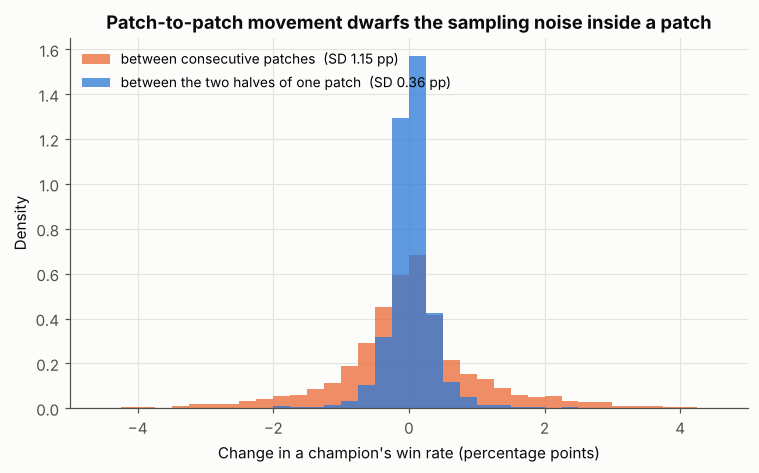

In [9]:
# Figure 3: within-patch (noise) vs between-patch (real change) movement
between = (W.diff(axis=1).stack() * 100)
within = (typ.wr1 - typ.wr2) * 100
bins = np.arange(-6, 6.01, 0.25)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.hist(between, bins=bins, density=True, color=C["orange"], alpha=0.75, label=f"between consecutive patches  (SD {between.std():.2f} pp)")
ax.hist(within, bins=bins, density=True, color=C["blue"], alpha=0.75, label=f"between the two halves of one patch  (SD {within.std():.2f} pp)")
ax.set_xlim(-5, 5); ax.set_xlabel("Change in a champion's win rate (percentage points)"); ax.set_ylabel("Density")
ax.set_title("Patch-to-patch movement dwarfs the sampling noise inside a patch")
ax.legend(loc="upper left", fontsize=9)
save(fig, "fig3_noise_vs_change.png")

Even as a lower bound, the implied volume is tens of thousands of Mayhem games per day (about 80,000), and a whole-patch win rate is good to roughly +/-0.2 pp. The distribution of changes between consecutive patches (SD 1.2 pp) is three to four times wider than the noise inside a patch (SD 0.3 to 0.4 pp), with long tails of real reworks reaching +/-4 pp; in variance terms, sampling noise accounts for under 10% of the patch-to-patch movement. **Essentially everything that moves between patches is signal.**

That reframes the tier-list design question. Averaging patches is a remedy for noise; here there is almost none, so averaging can only blur real changes.

## 4. What is the best forecast of next patch's win rate?

Treat each patch *t + 1* as a forecasting target and compare simple predictors built from patches up to *t*:

- the latest patch alone;
- the plain average of the last *k* patches (DeepARAM's "combine patches" option, roughly);
- an exponentially weighted moving average with smoothing *alpha* (newest patch weight);
- two baselines: "everyone is 49.3%" and the champion's all-time mean so far.

Scoring: mean absolute error in pp over champions, averaged over the 23 target patches (fewer for long windows, so the *k*-window results are also reported on the common set of targets).

In [10]:
T = len(ORDER)
def mae(pred, t):           # error of predicting patch t from `pred`
    m = pred.notna() & W[t].notna()
    return float((pred[m] - W[t][m]).abs().mean() * 100)

results = {}
# plain windows
for k in [1, 2, 3, 4, 6, 8, 12]:
    results[f"last {k} patch{'es' if k > 1 else ''}"] = {t: mae(W[list(range(t - k, t))].mean(axis=1), t) for t in range(k, T)}
# baselines
results["constant 49.3%"] = {t: mae(pd.Series(bp.win_rate.mean(), index=W.index), t) for t in range(1, T)}
results["all patches so far"] = {t: mae(W[list(range(0, t))].mean(axis=1), t) for t in range(1, T)}
# EWMA
for a in [0.5, 0.7, 0.8, 0.9, 0.95]:
    s = W[0].copy(); out = {}
    for t in range(1, T):
        out[t] = mae(s, t)
        s = (a * W[t] + (1 - a) * s).where(W[t].notna(), W[t]).fillna(s)
    results[f"EWMA alpha={a}"] = out
R = pd.DataFrame(results)
common = R.loc[12:]          # targets every method can score (patch index 12 = 16.10 onwards)
summary = pd.DataFrame({"MAE all targets (pp)": R.mean(), "MAE common 12 targets (pp)": common.mean(), "targets": R.count()}).round(3)
summary

,MAE all targets (pp),MAE common 12 targets (pp),targets
last 1 patch,0.754,0.674,23
last 2 patches,0.805,0.792,22
last 3 patches,0.877,0.909,21
last 4 patches,0.943,1.011,20
last 6 patches,1.083,1.177,18
last 8 patches,1.183,1.267,16
last 12 patches,1.391,1.391,12
constant 49.3%,2.534,2.623,23
all patches so far,1.380,1.537,23
EWMA alpha=0.5,0.856,0.815,23


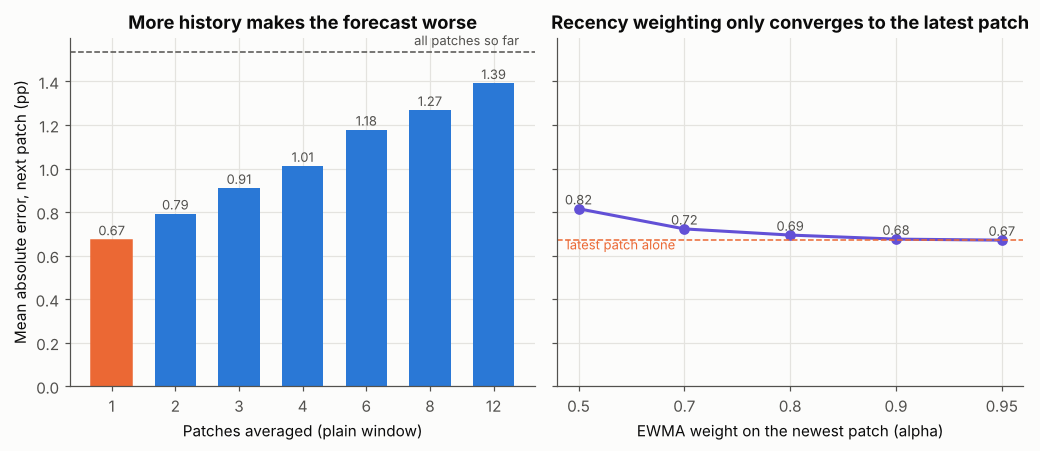

In [11]:
ks = [1, 2, 3, 4, 6, 8, 12]
win_mae = [common[f"last {k} patch{'es' if k > 1 else ''}"].mean() for k in ks]
alphas = [0.5, 0.7, 0.8, 0.9, 0.95]
ew_mae = [common[f"EWMA alpha={a}"].mean() for a in alphas]

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), sharey=True)
ax = axes[0]
bars = ax.bar([str(k) for k in ks], win_mae, color=C["blue"], width=0.65)
bars[0].set_color(C["orange"])
for b, v in zip(bars, win_mae):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=8.5, color=C["ink2"])
ax.axhline(common["all patches so far"].mean(), color=C["ink2"], ls="--", lw=1)
ax.text(6.4, common["all patches so far"].mean() + 0.03, "all patches so far", ha="right", fontsize=8.5, color=C["ink2"])
ax.set_xlabel("Patches averaged (plain window)"); ax.set_ylabel("Mean absolute error, next patch (pp)")
ax.set_title("More history makes the forecast worse")
ax = axes[1]
ax.plot([str(a) for a in alphas], ew_mae, "o-", color=C["violet"], lw=2, ms=6)
for a, v in zip(alphas, ew_mae):
    ax.text(str(a), v + 0.02, f"{v:.2f}", ha="center", fontsize=8.5, color=C["ink2"])
ax.axhline(win_mae[0], color=C["orange"], ls="--", lw=1)
ax.text(0.02, win_mae[0] - 0.045, "latest patch alone", fontsize=8.5, color=C["orange"], transform=ax.get_yaxis_transform())
ax.set_xlabel("EWMA weight on the newest patch (alpha)"); ax.set_title("Recency weighting only converges to the latest patch")
ax.set_ylim(0, max(win_mae) * 1.15)
save(fig, "fig4_forecast_error.png")

The latest patch alone forecasts next patch to within **0.75 pp** on average over all 23 targets (0.67 pp on the 12 targets every window can score). Every plain window is worse, and the error grows steadily with window length: three patches 0.91 pp, twelve patches 1.39 pp on the common targets. The exponentially weighted average converges to the latest-patch error as alpha goes to 1 and never beats it, which is exactly what the noise analysis predicts: there is nothing to smooth. The naive baselines show how much information is in the history at all: a constant guess errs by 2.5 pp, so the latest patch removes about 70% of the uncertainty.

**Recommendation for the site.** A "live patch" tier list should default to the newest patch, not a multi-patch blend. Combining patches by game count is a remedy for small samples; on this feed it only costs accuracy. A blend only makes sense for a sparser source (another region, or a self-collected archive), and there it should weight recency, not volume.

## 5. Do players chase winners, or do winners get worse because they are played more?

Cross-sectionally, pick rate and win rate are positively correlated (Spearman about 0.37 on a typical patch): popular champions win more. Two explanations are both plausible in ARAM Mayhem, where champions are rolled randomly and then traded:

- **Popularity follows strength**: players keep (or trade for) champions that are winning, so a rise in win rate shows up as more picks a patch later.
- **Strength follows popularity**: more picks means more unpracticed players, which should *lower* the win rate on the next patch.

With champion-patch panel data the two can be separated by looking at *changes* and their timing. If a change in win rate on patch *t* predicts the change in pick rate on patch *t + 1*, but not vice versa, the first story holds. Pick rate is used on the log scale so that a 10% relative rise means the same thing for a 2% and a 12% champion.

In [12]:
dW = W.diff(axis=1) * 100                     # change in win rate, pp
dL = np.log(K).diff(axis=1) * 100             # change in pick rate, % (log points)
cl = []
for t in range(1, T - 1):
    d = pd.DataFrame({"dwr": dW[t], "dpick": dL[t], "dwr_next": dW[t + 1], "dpick_next": dL[t + 1]}).dropna()
    d["champion_id"] = d.index; d["t"] = t
    cl.append(d)
cl = pd.concat(cl, ignore_index=True)

fwd = stats.spearmanr(cl.dwr, cl.dpick_next)       # win-rate change -> next pick change
rev = stats.spearmanr(cl.dpick, cl.dwr_next)       # pick change -> next win-rate change
same = stats.spearmanr(cl.dwr, cl.dpick)
print(f"d win rate (t)  -> d pick (t+1): Spearman {fwd[0]:+.3f}, p = {fwd[1]:.1e}")
print(f"d pick (t)      -> d win rate (t+1): Spearman {rev[0]:+.3f}, p = {rev[1]:.2f}")
print(f"same patch, d win rate vs d pick:    Spearman {same[0]:+.3f}, p = {same[1]:.2f}   (n = {len(cl)})")

# the same in levels, with cluster-robust SEs: does this patch's win rate predict next patch's pick rate, holding current pick rate?
pairs["lpick"], pairs["lpick_next"] = np.log(pairs.pick), np.log(pairs.pick_next)
pairs["wr_pp"] = pairs.wr * 100
mp = smf.ols("lpick_next ~ lpick + wr_pp", pairs).fit(cov_type="cluster", cov_kwds={"groups": pairs["champion_id"]})
mw = smf.ols("wr_next ~ wr + lpick", pairs).fit(cov_type="cluster", cov_kwds={"groups": pairs["champion_id"]})
print(f"\nlog pick(t+1) ~ log pick(t) + win rate(t):  +1 pp of win rate -> {100*mp.params['wr_pp']:+.2f}% more picks next patch "
      f"(95% CI {100*mp.conf_int().loc['wr_pp',0]:+.2f} to {100*mp.conf_int().loc['wr_pp',1]:+.2f}, p = {mp.pvalues['wr_pp']:.1e})")
print(f"win rate(t+1) ~ win rate(t) + log pick(t):  doubling pick rate -> {100*np.log(2)*mw.params['lpick']:+.3f} pp next patch "
      f"(p = {mw.pvalues['lpick']:.2f})")

d win rate (t)  -> d pick (t+1): Spearman +0.214, p = 1.3e-40
d pick (t)      -> d win rate (t+1): Spearman -0.019, p = 0.24
same patch, d win rate vs d pick:    Spearman -0.004, p = 0.79   (n = 3785)

log pick(t+1) ~ log pick(t) + win rate(t):  +1 pp of win rate -> +0.48% more picks next patch (95% CI +0.34 to +0.62, p = 3.6e-11)
win rate(t+1) ~ win rate(t) + log pick(t):  doubling pick rate -> +0.028 pp next patch (p = 0.17)


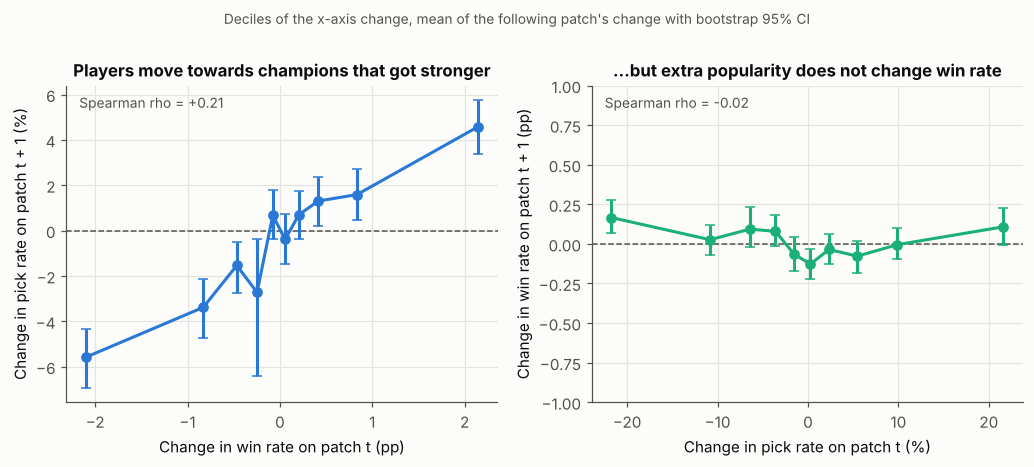

In [13]:
def binned(x, y, nb=10, B=400, seed=0):
    q = pd.qcut(x, nb, labels=False, duplicates="drop")
    rng = np.random.default_rng(seed); out = []
    for b in sorted(q.unique()):
        xs, ys = x[q == b].values, y[q == b].values
        boots = [rng.choice(ys, len(ys)).mean() for _ in range(B)]
        out.append((xs.mean(), ys.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)))
    return np.array(out)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, (x, y, xl, yl, title, col, r) in zip(axes, [
        (cl.dwr, cl.dpick_next, "Change in win rate on patch t (pp)", "Change in pick rate on patch t + 1 (%)",
         "Players move towards champions that got stronger", C["blue"], fwd[0]),
        (cl.dpick, cl.dwr_next, "Change in pick rate on patch t (%)", "Change in win rate on patch t + 1 (pp)",
         "...but extra popularity does not change win rate", C["aqua"], rev[0])]):
    b = binned(x, y)
    ax.axhline(0, color=C["ink2"], lw=1, ls="--")
    ax.errorbar(b[:, 0], b[:, 1], yerr=[b[:, 1] - b[:, 2], b[:, 3] - b[:, 1]], fmt="o-", color=col, lw=2, ms=6, capsize=3)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(title, fontsize=11)
    ax.text(0.03, 0.93, f"Spearman rho = {r:+.2f}", transform=ax.transAxes, fontsize=9, color=C["ink2"])
axes[1].set_ylim(-1, 1)   # comparable to a typical patch-to-patch change (SD 1.2 pp), so flat really looks flat
fig.suptitle("Deciles of the x-axis change, mean of the following patch's change with bootstrap 95% CI", fontsize=9, color=C["ink2"], y=1.0)
save(fig, "fig5_players_chase_winners.png")

The asymmetry is clean. Champions in the top decile of win-rate gains (+2 pp or more) are picked about 5% more (relative) on the following patch, those in the bottom decile about 6% less, and the relationship is close to monotone across deciles. In the other direction the deciles sit within +/-0.2 pp of zero, with confidence intervals that straddle it. In levels, holding current popularity fixed, **each extra point of win rate buys roughly half a percent more picks next patch**, while doubling a champion's pick rate shifts its next win rate by a few hundredths of a point and is not distinguishable from zero.

For a random-roll mode this is a nice result: the trade and reroll economy does respond to strength, but at a lag and only weakly (a 5 pp buff moves pick rate by a few percent, not by a tier), and the "popular champions get played badly" effect that plagues Summoner's Rift statistics is absent here.

## 6. Who is persistently strong, and who swings the most?

With the noise question settled, each champion's 24-patch history can be summarised honestly: the mean win rate with a 95% interval from the across-patch spread (the interval describes how the champion varies between patches, not sampling error), and the SD of patch-to-patch changes as a volatility score.

In [14]:
g = bp.groupby("champion_id")["win_rate"]
summ = pd.DataFrame({"name": names, "patches": g.size(), "mean": g.mean(), "sd": g.std(),
                     "volatility": W.diff(axis=1).std(axis=1), "latest": W[T - 1]})
summ["ci95"] = stats.t.ppf(0.975, summ.patches - 1) * summ.sd / np.sqrt(summ.patches)
summ["lo"], summ["hi"] = summ["mean"] - summ.ci95, summ["mean"] + summ.ci95
summ = summ[summ.patches >= 12]
top = summ.sort_values("mean", ascending=False).head(10)
bot = summ.sort_values("mean").head(10)
print("Most consistently strong (mean over patches, 95% CI):")
print((top[["name", "patches", "mean", "lo", "hi", "latest"]].set_index("name") * [1, 100, 100, 100, 100]).round(1).to_string())
print("\nMost consistently weak:")
print((bot[["name", "patches", "mean", "lo", "hi", "latest"]].set_index("name") * [1, 100, 100, 100, 100]).round(1).to_string())
print("\nMost volatile (SD of patch-to-patch change, pp):")
print((summ.sort_values("volatility", ascending=False).head(8)[["name", "volatility", "mean", "latest"]].set_index("name") * [100, 100, 100]).round(1).to_string())

Most consistently strong (mean over patches, 95% CI):
             patches  mean    lo    hi  latest
name                                          
Lillia            24  57.6  56.9  58.2    54.1
Vayne             24  55.4  54.3  56.6    50.0
Brand             24  55.1  54.0  56.3    48.9
Gwen              24  54.8  54.0  55.5    56.2
Seraphine         24  54.5  53.5  55.6    51.6
Hwei              24  54.2  53.8  54.6    52.7
TwistedFate       24  54.2  53.7  54.7    56.8
Yasuo             24  54.1  52.9  55.4    58.1
Kayn              24  54.1  53.6  54.6    53.1
Kayle             24  54.0  53.4  54.6    54.7

Most consistently weak:
          patches  mean    lo    hi  latest
name                                       
Bard           24  41.4  40.7  42.1    45.9
KSante         24  42.1  41.6  42.5    44.3
Akali          24  43.1  42.6  43.6    44.8
Leblanc        24  43.5  43.1  43.9    44.5
LeeSin         24  43.5  42.6  44.4    45.8
Zac            24  44.8  44.5  45.0    44.6
Camil

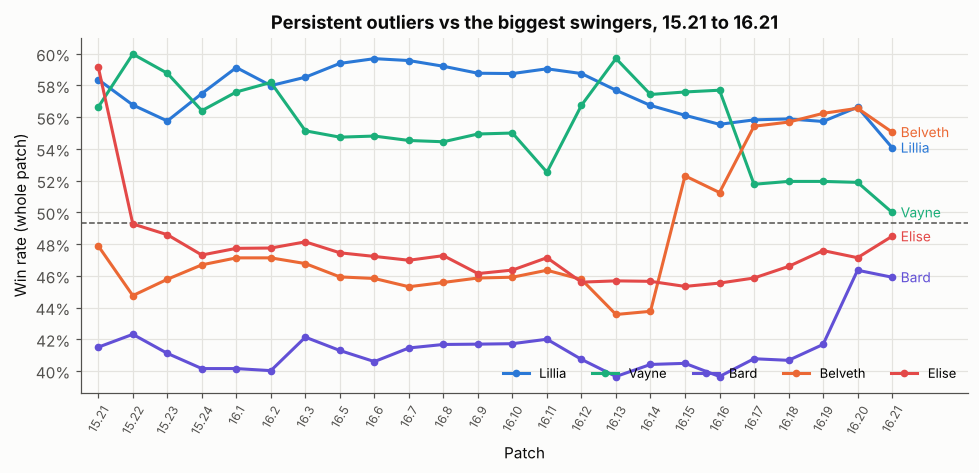

In [15]:
show = [top.index[0], top.index[1], bot.index[0]]
show += [c for c in summ.sort_values("volatility", ascending=False).index if c not in show][:2]
cols = [C["blue"], C["aqua"], C["violet"], C["orange"], "#e34948"]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.axhline(bp.win_rate.mean(), color=C["ink2"], lw=1, ls="--")
for cid, col in zip(show, cols):
    y = W.loc[cid]
    ax.plot(y.index, y.values, "o-", color=col, lw=2, ms=4, label=names[cid])
    last = y.dropna().index[-1]
    ax.text(last + 0.25, y[last], names[cid], color=col, fontsize=9, va="center")
ax.set_xticks(range(T)); ax.set_xticklabels(ORDER, rotation=60, fontsize=8)
ax.set_xlim(-0.5, T + 1.2); pct(ax, "y")
ax.set_xlabel("Patch"); ax.set_ylabel("Win rate (whole patch)")
ax.set_title("Persistent outliers vs the biggest swingers, 15.21 to 16.21")
ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(0.02))
ax.legend(loc="lower right", ncol=5, fontsize=8.5)
save(fig, "fig6_champion_trajectories.png")

## 7. Limitations

- **One server, one mode.** Tencent's China-server player base is huge (which is why the noise is so small) but its meta and skill distribution may differ from Riot regions. The persistence numbers are about *this* population.
- **No sample sizes.** Games were estimated as pick rate x window days, assuming similar daily volume (the same convention the repo already uses). The split-half calculation inherits that assumption; the implied game count is a lower bound and should be read as an order of magnitude.
- **Patch windows are inferred** (jumps in cumulative numbers near Tencent's release dates). Two windows (15.23, 16.12) show mid-window changes; they are flagged, not fixed.
- **Lag correlations overlap.** The 12 lag correlations share underlying patches, so the curve fit's standard errors are optimistic. The qualitative finding (slow decay to a floor well above zero) is robust to dropping any single patch.
- **Mean absolute error as the only forecast metric.** Rank-based metrics (e.g. Spearman between forecast and actual tier order) tell the same story in this data but are not reported.
- **Causality in section 5** is argued from timing (Granger-style), not from an experiment. Confounders that hit win rate on patch *t* and pick rate on patch *t + 1* separately (a skin release, a popular streamer) would produce the same pattern.

## 8. Next steps

1. **Expose "latest patch" as the default tier-list window** on DeepARAM and move the multi-patch blend to an EWMA with alpha around 0.9. Measure the change by re-running section 4 after each patch.
2. **Model the decay per champion class** (tank, mage, marksman...) using `simulator/data/champions.json` roles: do balance changes hit some classes harder or decay faster?
3. **Link big moves to patch notes.** `data/pbe/` holds datamined changes for recent patches; matching the largest patch-to-patch moves (section 6) to the changelist would turn the "it is all real" finding into a per-change effect size.
4. **Augment pool changes** are the other source of real movement. Repeating the split-half check around known augment additions would show whether they move champion win rates as much as number tweaks do.
5. **Validate on a second region** once a Riot-API-based Mayhem feed is available, to see whether the half-life and the "players chase winners" lag replicate outside China.